# TP4 — Classification et évaluation

**Cours :** Introduction au Machine Learning — 60 h — Licence 3 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 3 h · **Barème :** 15 points

---

## Objectifs

- Évaluer un classifieur sur des données déséquilibrées.
- Tracer ROC et précision-rappel.
- Choisir un seuil par le coût des erreurs.
- Mesurer l'effet de la pondération des classes.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter dans l'ordre ; tout tourne sur CPU en moins d'une minute.
- Les cellules **« À vous »** sont évaluées. Graine fixée.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.random.seed(4112)
print('environnement pret')

environnement pret


## 1. Un jeu déséquilibré

5\,000 dossiers, **5 % de positifs** (fraude, décrochage, panne). C'est le régime
réel de la plupart des problèmes de détection.

In [2]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=5000, n_features=5, n_informative=3,
                           n_redundant=0, weights=[0.95, 0.05],
                           flip_y=0.01, random_state=4112)
print("positifs :", int(y.sum()), f"({100*y.mean():.1f} %)")
print("forme    :", X.shape)

positifs : 273 (5.5 %)
forme    : (5000, 5)


## 2. Découper, puis la référence naïve

In [3]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.3, random_state=4112, stratify=y)

# le modele qui ne detecte jamais rien
acc_naif = float((yte == 0).mean())
print(f"exactitude d'un modele tout-negatif : {acc_naif:.4f}")

exactitude d'un modele tout-negatif : 0.9453


## 3. Régression logistique : les cinq métriques

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

modele = Pipeline([("sc", StandardScaler()),
                   ("lr", LogisticRegression(max_iter=2000))]).fit(Xtr, ytr)
proba = modele.predict_proba(Xte)[:, 1]
pred = (proba >= .5).astype(int)

print(f"exactitude : {accuracy_score(yte, pred):.4f}")
print(f"precision  : {precision_score(yte, pred):.4f}")
print(f"rappel     : {recall_score(yte, pred):.4f}")
print(f"F1         : {f1_score(yte, pred):.4f}")
print(f"AUC        : {roc_auc_score(yte, proba):.4f}")
print("\nmatrice :\n", confusion_matrix(yte, pred))

exactitude : 0.9833
precision  : 1.0000
rappel     : 0.6951
F1         : 0.8201
AUC        : 0.9179

matrice :
 [[1418    0]
 [  25   57]]


## 4. Le seuil déplace tout

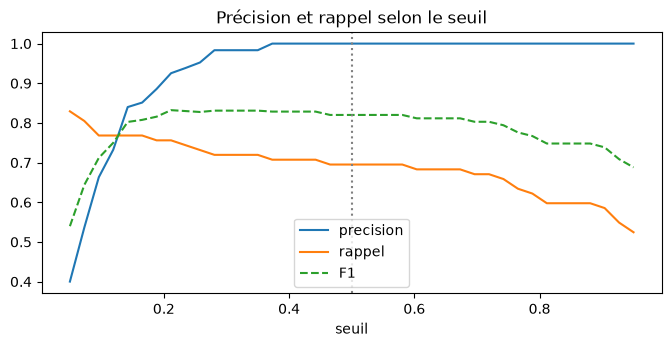

seuil du F1 maximal : 0.21


In [5]:
seuils = np.linspace(.05, .95, 40)
prec = [precision_score(yte, (proba >= s).astype(int), zero_division=0) for s in seuils]
rec  = [recall_score(yte, (proba >= s).astype(int)) for s in seuils]
f1s  = [f1_score(yte, (proba >= s).astype(int), zero_division=0) for s in seuils]

plt.figure(figsize=(8, 3.4))
plt.plot(seuils, prec, label="precision")
plt.plot(seuils, rec, label="rappel")
plt.plot(seuils, f1s, "--", label="F1")
plt.axvline(.5, color="grey", ls=":")
plt.xlabel("seuil"); plt.legend(); plt.title("Précision et rappel selon le seuil")
plt.show()
print("seuil du F1 maximal :", round(float(seuils[int(np.argmax(f1s))]), 2))

## 5. Choisir le seuil par le coût

Une fraude manquée coûte **10 fois** plus qu'une fausse alerte.

In [6]:
C_FP, C_FN = 1, 10
couts = []
for s in seuils:
    tn, fp, fn, tp = confusion_matrix(yte, (proba >= s).astype(int)).ravel()
    couts.append(C_FP * fp + C_FN * fn)

k = int(np.argmin(couts))
print(f"seuil optimal : {seuils[k]:.2f} | cout : {couts[k]}")
print(f"cout au seuil 0,50 : {couts[int(np.argmin(np.abs(seuils - .5)))]}")

seuil optimal : 0.17 | cout : 201
cout au seuil 0,50 : 250


## 6. ROC et précision-rappel

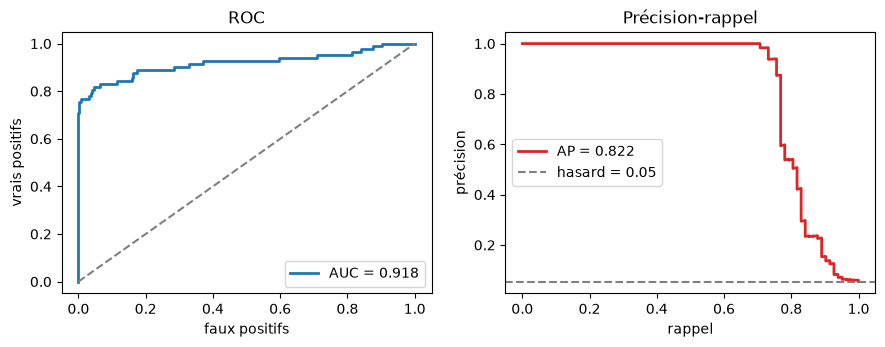

In [7]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score

fpr, tpr, _ = roc_curve(yte, proba)
pr, rc, _ = precision_recall_curve(yte, proba)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
axes[0].plot(fpr, tpr, lw=2, label=f"AUC = {auc(fpr, tpr):.3f}")
axes[0].plot([0, 1], [0, 1], "--", color="grey")
axes[0].set_xlabel("faux positifs"); axes[0].set_ylabel("vrais positifs")
axes[0].set_title("ROC"); axes[0].legend()
axes[1].plot(rc, pr, lw=2, color="#DC2626", label=f"AP = {average_precision_score(yte, proba):.3f}")
axes[1].axhline(yte.mean(), color="grey", ls="--", label=f"hasard = {yte.mean():.2f}")
axes[1].set_xlabel("rappel"); axes[1].set_ylabel("précision")
axes[1].set_title("Précision-rappel"); axes[1].legend()
plt.show()

## 7. La pondération des classes

In [8]:
m_bal = Pipeline([("sc", StandardScaler()),
                    ("lr", LogisticRegression(max_iter=2000, class_weight="balanced"))]).fit(Xtr, ytr)
pred_b = m_bal.predict(Xte)

comparaison = pd.DataFrame({
    "sans poids": [accuracy_score(yte, pred), f1_score(yte, pred), recall_score(yte, pred)],
    "avec poids": [accuracy_score(yte, pred_b), f1_score(yte, pred_b), recall_score(yte, pred_b)],
}, index=["exactitude", "F1", "rappel"])
print(comparaison.round(3).to_string())

            sans poids  avec poids
exactitude       0.983       0.949
F1               0.820       0.624
rappel           0.695       0.780


## 8. Les probabilités sont-elles calibrées ?

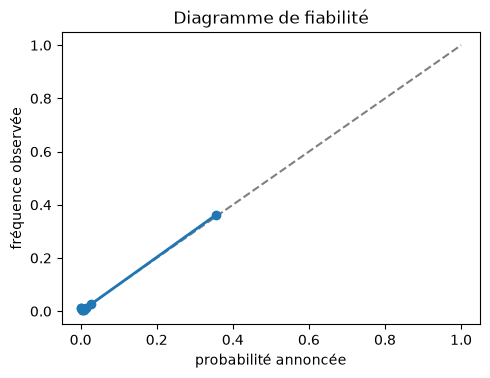

ecart maximal : 0.01


In [9]:
from sklearn.calibration import calibration_curve
frac, moy = calibration_curve(yte, proba, n_bins=8, strategy="quantile")
plt.figure(figsize=(5.4, 3.8))
plt.plot([0, 1], [0, 1], "--", color="grey")
plt.plot(moy, frac, "o-", lw=2)
plt.xlabel("probabilité annoncée"); plt.ylabel("fréquence observée")
plt.title("Diagramme de fiabilité")
plt.show()
print("ecart maximal :", round(float(np.max(np.abs(frac - moy))), 3))

## 9. À vous (noté)

**1.** Calculez le coût total au seuil qui maximise le $F_1$, puis comparez-le
au coût du seuil optimal trouvé en section 5. Lequel est le plus faible ?

**2.** Réentraînez le modèle avec `class_weight={0:1, 1:25}`. Que deviennent
précision, rappel et coût au seuil 0,5 ?

**3.** Expliquez en deux phrases pourquoi l'exactitude d'un modèle qui ne
détecte jamais rien est ici de 0,95.

In [10]:
# ---- A VOUS ----
# 1)
# 2)
# 3)

## 10. Ce qu'il faut retenir

| Geste | Pourquoi |
|---|---|
| comparer à un modèle naïf | sinon le score ne veut rien dire |
| regarder la matrice | elle localise les erreurs |
| choisir le seuil par le coût | une métrique abstraite ne décide pas |
| préférer PR à ROC si très déséquilibré | les vrais négatifs gonflent la ROC |
| vérifier la calibration | un seuil calculé suppose des probabilités justes |